#Machine Learning Concepts Assignment Notebook
##Created by Saul Smith, Student Number 22468499

## Importing Packages and Loading Notebook

In [148]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [149]:
!ls "/content/drive/My Drive/Colab Notebooks/MLC_Assignment_2025"

adverts.csv  MLC_22468499_Notebook.ipynb


In [150]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
# Importing Packages we need to use

path = "/content/drive/My Drive/Colab Notebooks/MLC_Assignment_2025/adverts.csv"
df = pd.read_csv(path)

# Quick check
print("Data shape:", df.shape)
df.head()

Data shape: (402005, 12)


,public_reference,mileage,reg_code,standard_colour,standard_make,standard_model,vehicle_condition,year_of_registration,price,body_type,crossover_car_and_van,fuel_type
0,202006039777689,0.0,NaN,Grey,Volvo,XC90,NEW,NaN,73970,SUV,False,Petrol Plug-in Hybrid
1,202007020778260,108230.0,61,Blue,Jaguar,XF,USED,2011.0,7000,Saloon,False,Diesel
2,202007020778474,7800.0,17,Grey,SKODA,Yeti,USED,2017.0,14000,SUV,False,Petrol
3,202007080986776,45000.0,16,Brown,Vauxhall,Mokka,USED,2016.0,7995,Hatchback,False,Diesel
4,202007161321269,64000.0,64,Grey,Land Rover,Range Rover Sport,USED,2015.0,26995,SUV,False,Diesel


# Important - Reg Code Re-Adjustment for 2020

In [151]:
# Calculate car age as of 2020, not 2025
df['car_age_2020'] = 2020 - df['year_of_registration']

# Avoid division by zero for brand new cars
df['car_age_2020'] = df['car_age_2020'].replace(0, 1)

# Create a few derived features
df['price_per_mile'] = df['price'] / df['mileage']
df['mileage_per_year'] = df['mileage'] / df['car_age_2020']

# Simplify vehicle condition into a binary variable
df['is_used'] = df['vehicle_condition'].apply(lambda x: 1 if str(x).upper() == 'USED' else 0)

# Create an age group variable
df['age_category'] = pd.cut(
    df['car_age_2020'],
    bins=[0, 3, 7, 20, 100],
    labels=['New', 'Mid', 'Old', 'Very Old']
)

Cars with value 0 = New, Cars with value 1 = Used, this will be useful when data cleaning further down the line.

In [152]:
# Create an age group variable in the full dataframe
df['car_age_2020'] = 2020 - df['year_of_registration']
df['car_age_2020'] = df['car_age_2020'].replace(0, 1) # Avoid division by zero

df['age_category'] = pd.cut(
    df['car_age_2020'],
    bins=[0, 3, 7, 20, 100],
    labels=['New', 'Mid', 'Old', 'Very Old']
)


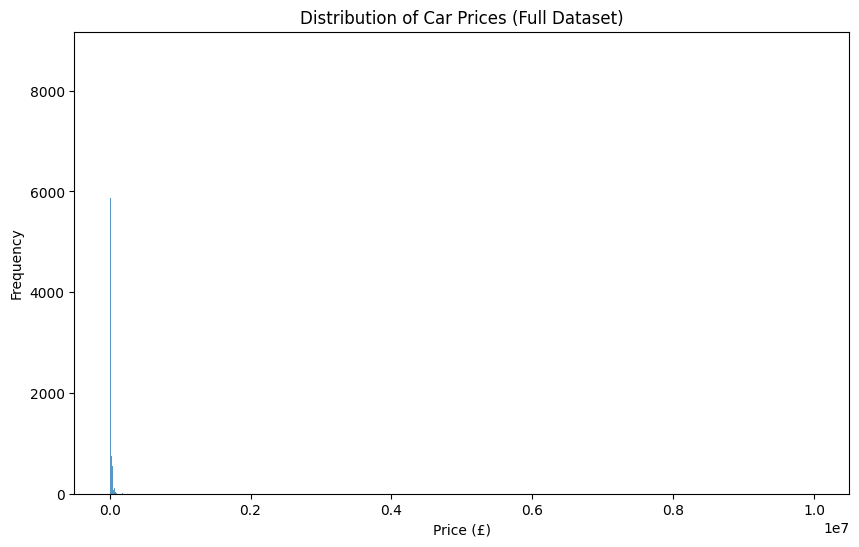

In [153]:

# Distribution of Car Prices
plt.figure(figsize=(10, 6))
sns.histplot(df['price'])
plt.title('Distribution of Car Prices (Full Dataset)')
plt.xlabel('Price (£)')
plt.ylabel('Frequency')
plt.show()

In [154]:
# Sample 5,000 rows for faster plotting
df_sample = df.sample(5000, random_state=42).copy()

# Calculate car age as of 2020, not 2025
df_sample['car_age_2020'] = 2020 - df_sample['year_of_registration']

# Avoid division by zero for brand new cars
df_sample['car_age_2020'] = df_sample['car_age_2020'].replace(0, 1)

In [155]:
# 1. Define the Parser Function
def parse_reg_code(reg_code):
    if pd.isna(reg_code):
        return np.nan
    str_reg_code = str(reg_code).strip()
    if not str_reg_code.isdigit() or len(str_reg_code) != 2:
        return np.nan
    code_int = int(str_reg_code)
    # 01-49 = 2000s, 51-99 = 2000s (minus 50)
    if 1 <= code_int <= 49:
        return 2000 + code_int
    elif 51 <= code_int <= 99:
        return 2000 + (code_int - 50)
    return np.nan

# 2. Apply the parser to fill the year_of_registration gaps
df['derived_year'] = df['reg_code'].apply(parse_reg_code)
df['year_of_registration'] = df['year_of_registration'].fillna(df['derived_year'])

# 3. Recalculate car_age_2020 using the newly filled years
df['car_age_2020'] = 2020 - df['year_of_registration']

# 4. Final Imputation Safety Net (Median)
# This handles cases where both year_of_registration AND reg_code were missing
df['year_of_registration'] = df['year_of_registration'].fillna(df['year_of_registration'].median())
df['car_age_2020'] = 2020 - df['year_of_registration']

# 5. Drop helper column
df.drop('derived_year', axis=1, inplace=True)

print(f"Remaining nulls in car_age_2020: {df['car_age_2020'].isnull().sum()}")

Remaining nulls in car_age_2020: 0


# Section 1 - Data Exploration & Predictive Power
I first need to perform an initial data exploration on the dataframe examining its structure with df.info() and df.describe(), identifying and calculating the percentage of missing values, visualising the distributions of 'mileage' and 'price' with histograms,

This will help me to summarise the findings regarding data quality, distributions, and potential areas for further investigation.

## Explore Data Structure

### Subtask:
Examine the DataFrame's information df.info() to understand column names, data types, and non-null counts. Also, display descriptive statistics for numerical columns using df.describe().


In [156]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 402005 entries, 0 to 402004
Data columns (total 17 columns):
 #   Column                 Non-Null Count   Dtype   
---  ------                 --------------   -----   
 0   public_reference       402005 non-null  int64   
 1   mileage                401878 non-null  float64 
 2   reg_code               370148 non-null  object  
 3   standard_colour        396627 non-null  object  
 4   standard_make          402005 non-null  object  
 5   standard_model         402005 non-null  object  
 6   vehicle_condition      402005 non-null  object  
 7   year_of_registration   402005 non-null  float64 
 8   price                  402005 non-null  int64   
 9   body_type              401168 non-null  object  
 10  crossover_car_and_van  402005 non-null  bool    
 11  fuel_type              401404 non-null  object  
 12  car_age_2020           402005 non-null  float64 
 13  price_per_mile         401878 non-null  float64 
 14  mileage_per_year    

In [157]:
print(df.describe())

       public_reference        mileage  year_of_registration         price  \
count      4.020050e+05  401878.000000         402005.000000  4.020050e+05   
mean       2.020071e+14   37743.595656           2015.091536  1.734197e+04   
std        1.691662e+10   34831.724018              7.635067  4.643746e+04   
min        2.013072e+14       0.000000            999.000000  1.200000e+02   
25%        2.020090e+14   10481.000000           2014.000000  7.495000e+03   
50%        2.020093e+14   28629.500000           2016.000000  1.260000e+04   
75%        2.020102e+14   56875.750000           2018.000000  2.000000e+04   
max        2.020110e+14  999999.000000           2045.000000  9.999999e+06   

        car_age_2020  price_per_mile  mileage_per_year        is_used  
count  402005.000000    4.018780e+05     368586.000000  402005.000000  
mean        4.908464             inf       8581.100622       0.922267  
std         7.635067             NaN       5500.678436       0.267751  
min      

## **Missing Values & Percentage Calculation**:
To identify and calculate the percentage of missing values in the DataFrame, I will use a combination of    
.isnull(), .sum(), and division by len(df) to get the percentage.



In [158]:
missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df)) * 100

# Display missing values and their percentages for columns with missing data
missing_info = pd.DataFrame({
    'Missing Value Count': missing_values,
    'Missing Value Percentage': missing_percentage
})

print("Missing Values and Percentages:")
print(missing_info[missing_info['Missing Value Count'] > 0].sort_values(by='Missing Value Percentage', ascending=False))

Missing Values and Percentages:
                  Missing Value Count  Missing Value Percentage
mileage_per_year                33419                  8.313081
age_category                    33329                  8.290693
reg_code                        31857                  7.924528
standard_colour                  5378                  1.337794
body_type                         837                  0.208206
fuel_type                         601                  0.149501
mileage                           127                  0.031592
price_per_mile                    127                  0.031592


# Section 1

##Section 1.1 - Analysis of Distributions

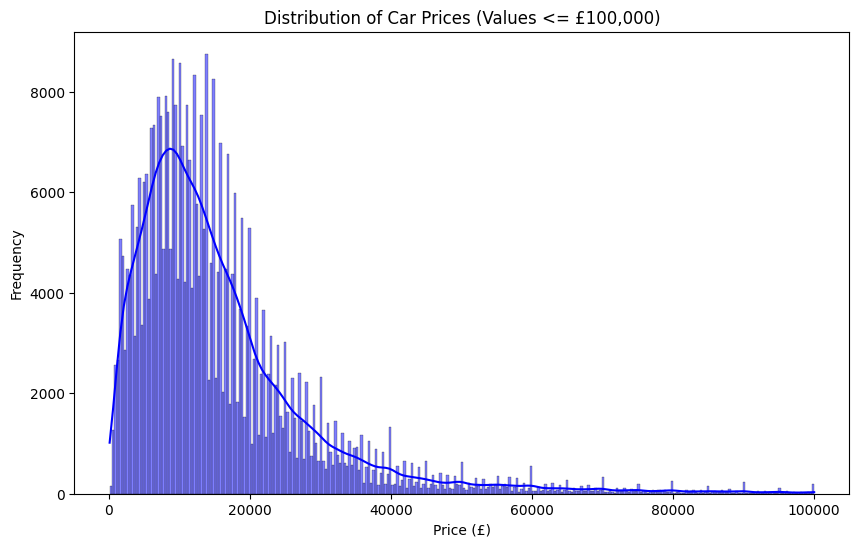

In [159]:
# Filter to ensure the plot is readable
plt.figure(figsize=(10, 6))
sns.histplot(df[df['price'] <= 100000]['price'], kde=True, color='blue')

plt.title('Distribution of Car Prices (Values <= £100,000)')
plt.xlabel('Price (£)')
plt.ylabel('Frequency')
plt.show()

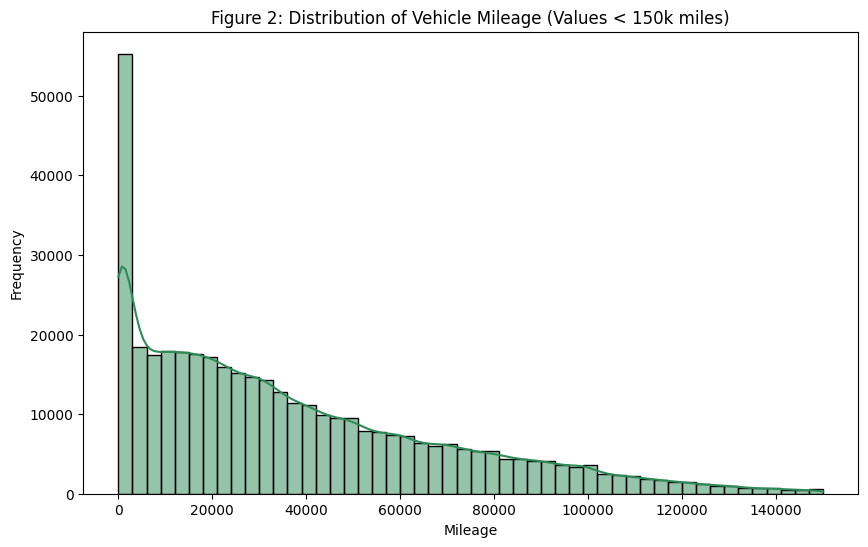

In [160]:
plt.figure(figsize=(10, 6))
# Capping mileage at 150k to avoid 'squashing' the plot
sns.histplot(df[df['mileage'] <= 150000]['mileage'], bins=50, kde=True, color='seagreen')
plt.title('Figure 2: Distribution of Vehicle Mileage (Values < 150k miles)', fontsize=12)
plt.xlabel('Mileage')
plt.ylabel('Frequency')
plt.show()

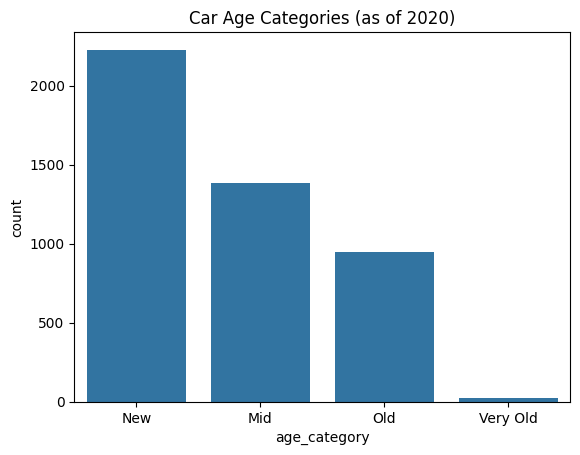

In [161]:
# Car age distribution (as of 2020)
sns.countplot(x='age_category', data=df_sample)
plt.title('Car Age Categories (as of 2020)')
plt.show()

## Distribution of Categories - Further Exploration for Section 1

**Reasoning**:
To visualize the frequency distribution of the specified categorical columns, I will create bar plots for 'standard_make', 'standard_colour', 'vehicle_condition', 'body_type', and 'fuel_type'. Given that some columns might have many unique values, I will adjust the figure size dynamically and select the top N categories for columns like 'standard_make' and 'standard_colour' to ensure readability, while plotting all categories for columns with fewer unique values.



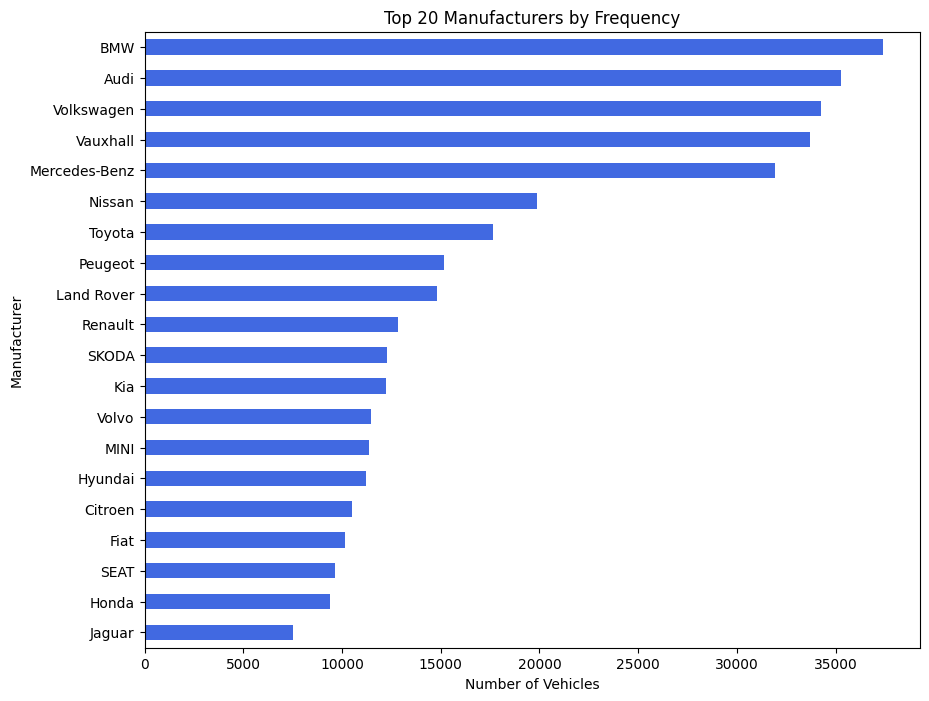

In [162]:
# Simple Horizontal Bar Chart for Manufacturers
plt.figure(figsize=(10, 8)) # Taller figure to fit more rows
df['standard_make'].value_counts().nlargest(20).plot(kind='barh', color='royalblue').invert_yaxis()
plt.title('Top 20 Manufacturers by Frequency')
plt.xlabel('Number of Vehicles')
plt.ylabel('Manufacturer')
plt.show()

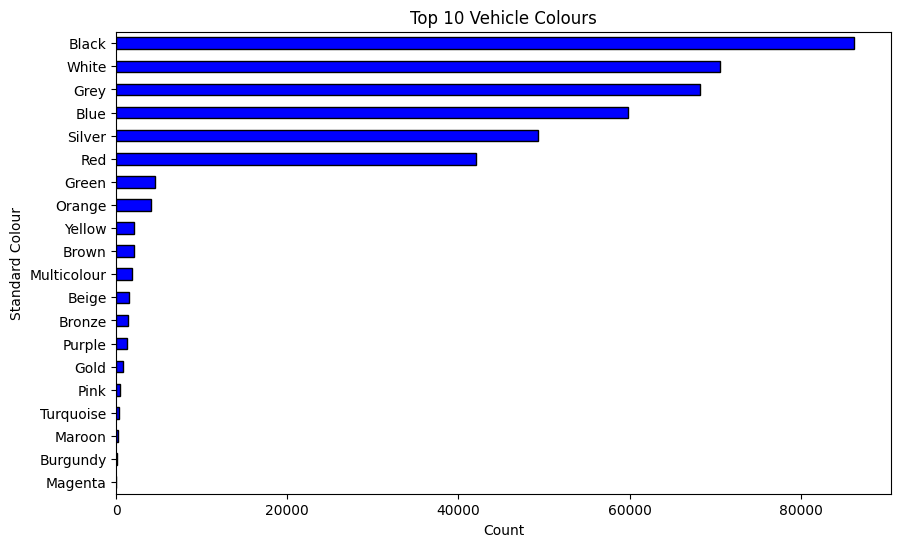

In [163]:
# Simple Horizontal Bar Chart for Colours
plt.figure(figsize=(10, 6))
df['standard_colour'].value_counts().nlargest(20).plot(kind='barh', color='blue', edgecolor='black').invert_yaxis()
plt.title('Top 10 Vehicle Colours')
plt.xlabel('Count')
plt.ylabel('Standard Colour')
plt.show()

/tmp/ipython-input-1867403896.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='vehicle_condition', palette='magma', order=df['vehicle_condition'].value_counts().index)


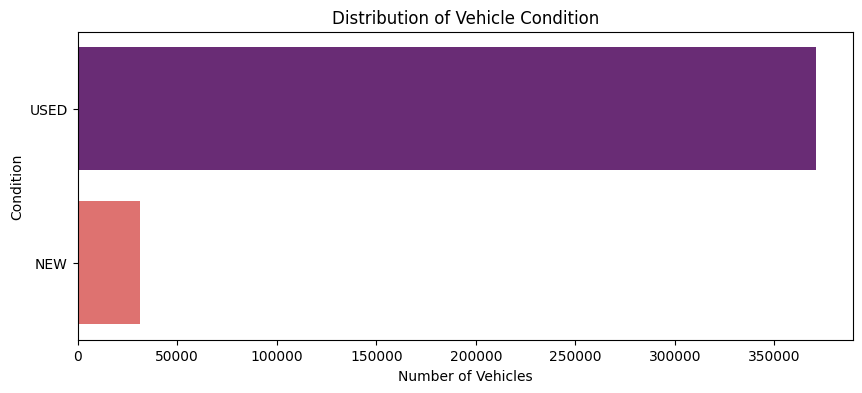

In [164]:
# Simple Horizontal Plot for Vehicle Condition
plt.figure(figsize=(10, 4))
sns.countplot(data=df, y='vehicle_condition', palette='magma', order=df['vehicle_condition'].value_counts().index)
plt.title('Distribution of Vehicle Condition')
plt.xlabel('Number of Vehicles')
plt.ylabel('Condition')
plt.show()

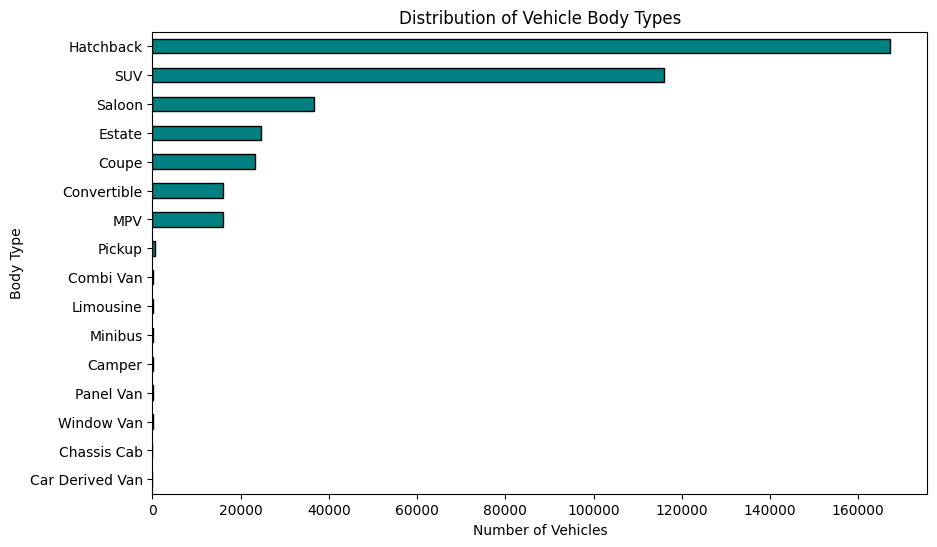

In [165]:
# Simple Horizontal Bar Chart for Body Type
plt.figure(figsize=(10, 6))
df['body_type'].value_counts().plot(kind='barh', color='teal', edgecolor='black').invert_yaxis()
plt.title('Distribution of Vehicle Body Types')
plt.xlabel('Number of Vehicles')
plt.ylabel('Body Type')
plt.show()

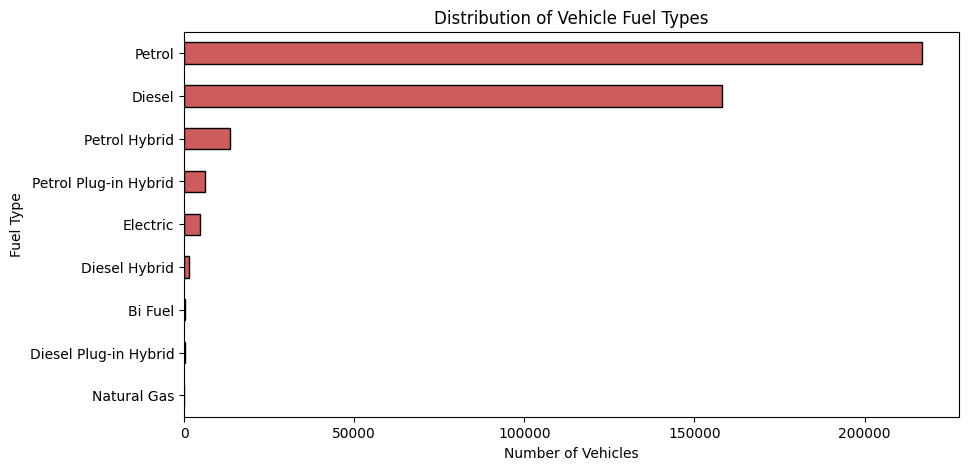

In [166]:
# Simple Horizontal Bar Chart for Fuel Type
plt.figure(figsize=(10, 5))
df['fuel_type'].value_counts().plot(kind='barh', color='indianred', edgecolor='black').invert_yaxis()
plt.title('Distribution of Vehicle Fuel Types')
plt.xlabel('Number of Vehicles')
plt.ylabel('Fuel Type')
plt.show()

## Summary of Initial Data Exploration

### Data Quality and Missing Values:
- The dataset contains **402,005** entries and **12** columns.

- **year_of_registration** and **reg_code** have the highest percentage of missing values, at approximately **8.29%** and **7.92%** respectively. These columns may require imputation or careful handling during analysis.

- **standard_colour** has about **1.34%** missing values, while **body_type**, **fuel_type**, and **mileage** have a relatively small number of missing values (less than 1%).

- Columns like public_reference, standard_make, standard_model,
vehicle_condition, price, and crossover_car_and_van are complete with no missing data.

### Numerical Column Distributions (mileage):
- **mileage**: The distribution is heavily skewed to the right, with a large concentration of vehicles having low mileage (including 0 mileage, indicating new cars). There's a long tail extending to higher mileages, suggesting a diverse range of vehicle usage. The maximum mileage is a value of 999,999.

### Categorical Column Frequencies:
- **standard_make**: Ford, Volkswagen, and BMW appear to be the most common car manufacturers in the dataset, indicating their popularity.

- **standard_colour**: Black, White, and Grey are the most frequent car colours, consistent with general market trends.

- **vehicle_condition**: The vast majority of vehicles are 'USED', with a very small proportion being 'NEW'. This suggests the dataset primarily consists of second-hand car listings.

- **body_type**: SUV, Hatchback, and Saloon are the dominant body types, reflecting current consumer preferences for practical and versatile vehicles.

- **fuel_type**: Petrol and Diesel are the most common fuel types, followed by Hybrid and Electric, though the latter two have significantly lower counts. This indicates a market still largely dominated by traditional internal combustion engines, but with a growing presence of alternative fuel vehicles.

### Potential Areas for Further Investigation:
- **Missing Data Handling**: Strategies for year_of_registration and reg_code (e.g., imputation, removal) need to be determined.

- **Outlier Detection/Treatment**: The skewed distributions of mileage and price suggest the presence of outliers that might require transformation or specific modeling approaches.

- **Feature Engineering**: year_of_registration could be used to calculate vehicle age, which might be a more direct predictor of price or mileage.

- **Categorical Variable Management**: For standard_make and standard_colour, which have many unique values, combining less frequent categories or using appropriate encoding methods will be important.

This initial exploration provides a solid foundation for understanding the dataset's characteristics and guiding subsequent data cleaning and feature engineering steps.

## Section 1.2 - Analysis of Predictive Powers

### Example 1: Mileage v Price (Correlation)

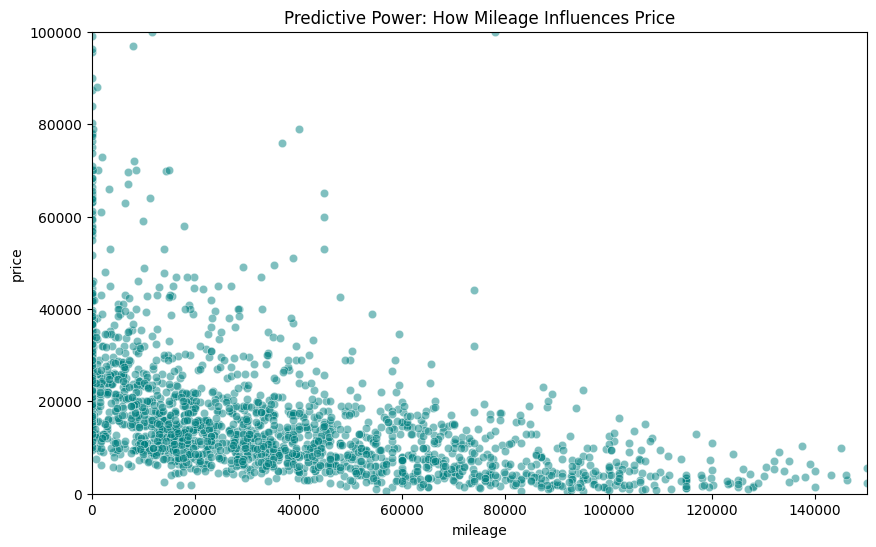

In [167]:
plt.figure(figsize=(10, 6))
# Sampling 2000 points so the scatter plot isn't a solid block of ink, and reduces computational time
sns.scatterplot(data=df.sample(2000), x='mileage', y='price', alpha=0.5, color='teal')
plt.title('Predictive Power: How Mileage Influences Price')
plt.xlim(0, 150000) # Keep it readable
plt.ylim(0, 100000)
plt.show()

### Example 2: Vehicle Age v Price


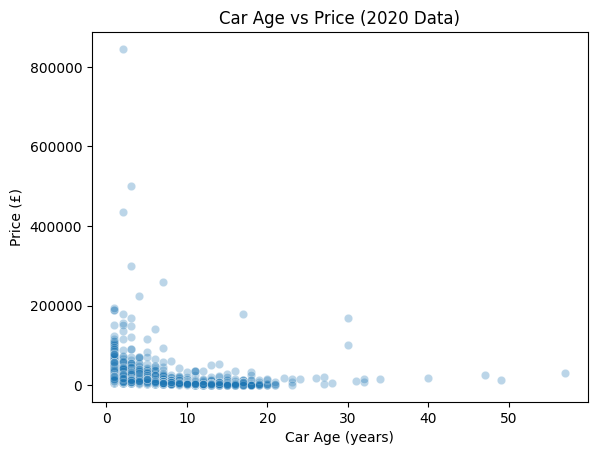

In [168]:
# Price vs Age
sns.scatterplot(
    x='car_age_2020',
    y='price',
    data=df_sample,
    alpha=0.3  # makes overlapping points lighter
)
plt.title('Car Age vs Price (2020 Data)')
plt.xlabel('Car Age (years)')
plt.ylabel('Price (£)')
plt.show()

### Example 3: Standard Make v Price

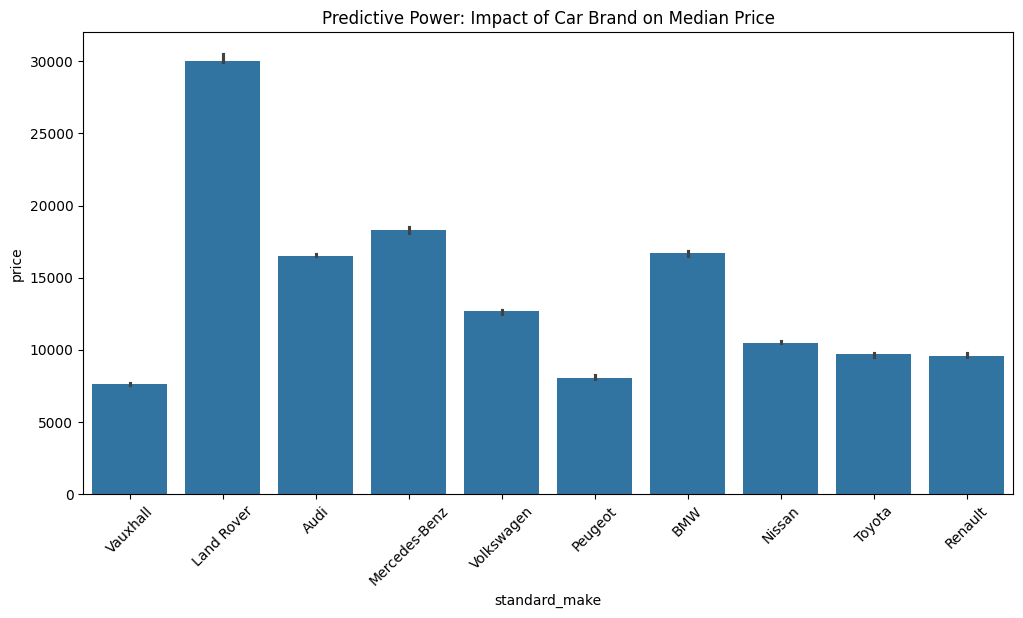

In [169]:
# Showing the top 10 most common makes to keep the chart clean
top_makes = df['standard_make'].value_counts().nlargest(10).index
plt.figure(figsize=(12, 6))
sns.barplot(data=df[df['standard_make'].isin(top_makes)], x='standard_make', y='price', estimator='median')
plt.title('Predictive Power: Impact of Car Brand on Median Price')
plt.xticks(rotation=45)
plt.show()

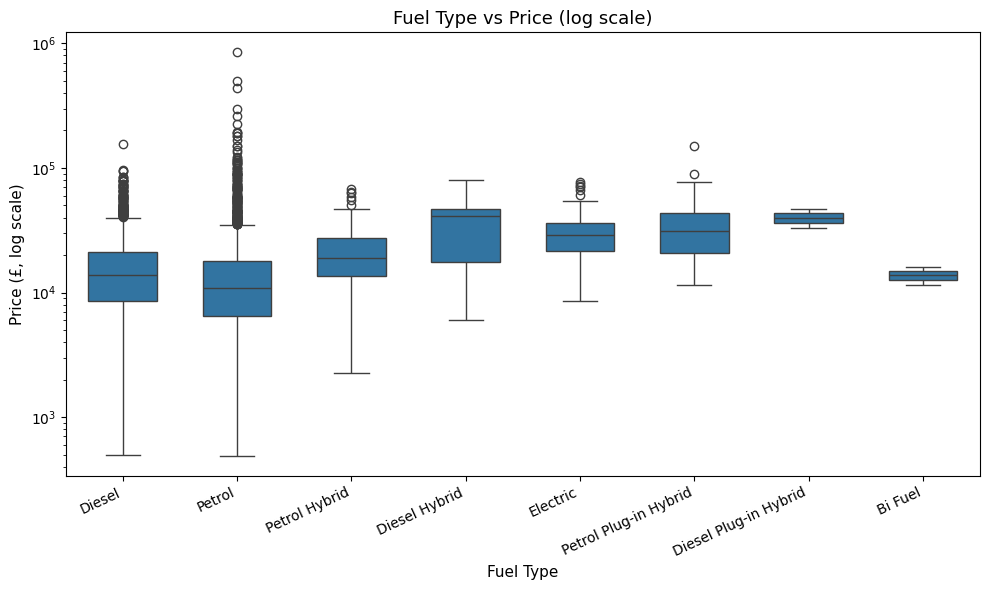

In [170]:
# Price by Fuel Type
plt.figure(figsize=(10, 6))#Widens figure

sns.boxplot(
    x='fuel_type',
    y='price',
    data=df_sample,
    width=0.6
)

plt.yscale('log')
plt.title('Fuel Type vs Price (log scale)', fontsize=13)
plt.xlabel('Fuel Type', fontsize=11)
plt.ylabel('Price (£, log scale)', fontsize=11)
plt.xticks(rotation=25, ha='right')#Rotate labels for clarity
plt.tight_layout()  #Prevent label cut-off
plt.show()

## Section 1.3 - Predictive Power


/tmp/ipython-input-3205663029.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_colour_viz, x='standard_colour', palette='viridis', order=top_colours)


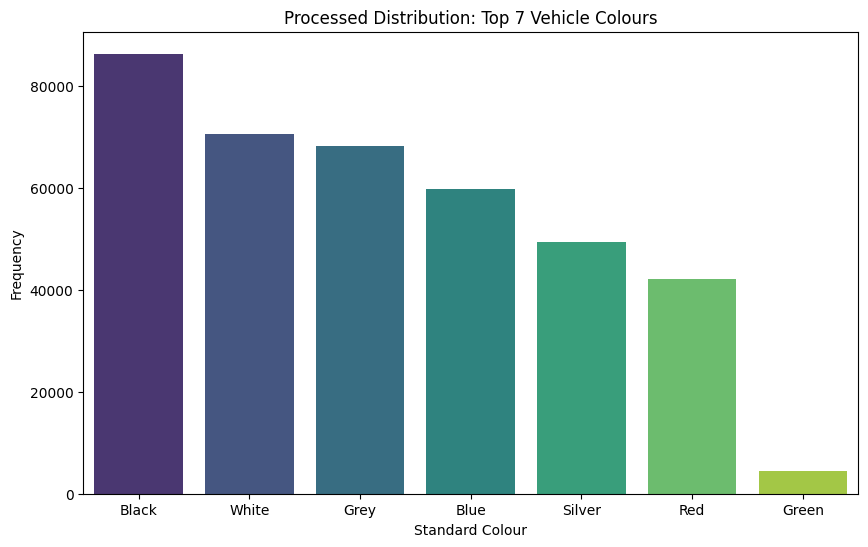

In [98]:
# 1.3 Example 3: Simplifying Categorical 'Noise' for Visualisation
# Find the top 7 most common colours
top_colours = df['standard_colour'].value_counts().nlargest(7).index

# Create a slice of data - only looking at these common colours
df_colour_viz = df[df['standard_colour'].isin(top_colours)]

plt.figure(figsize=(10, 6))
sns.countplot(data=df_colour_viz, x='standard_colour', palette='viridis', order=top_colours)
plt.title('Processed Distribution: Top 7 Vehicle Colours')
plt.xlabel('Standard Colour')
plt.ylabel('Frequency')
plt.show()

## Visualising Mileage in Split Ranges

As an alternative to logarithmic transformation or a generalised plot, I will now visualise the 'mileage' distribution by splitting it into distinct ranges.

This allows us to observe the details of the highly concentrated lower mileage values on a better scale, as well as the spread of higher mileage values, without the data being compressed or distorted by a log transformation.

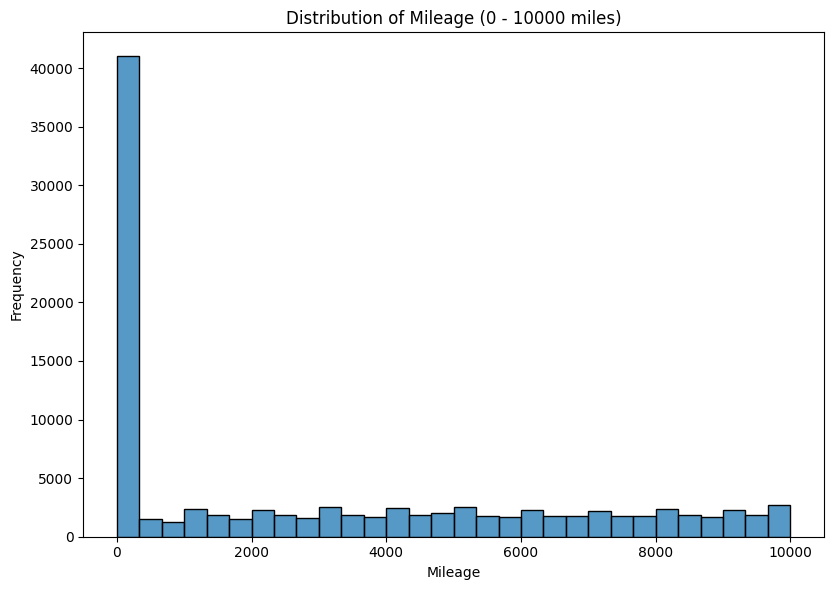

In [99]:
# Define a split point for mileage. Chosen 10,000 for demonstration.
split_point = 10000

# Create subplot for the two ranges
plt.figure(figsize=(16, 6))

# Subplot 1: Lower mileage range
plt.subplot(1, 2, 1)
# Filtered the DataFrame to include only mileage values below or equal to the split_point
# Drop NaN values before plotting
sns.histplot(df[df['mileage'] <= split_point]['mileage'].dropna(), bins=30)
plt.title(f'Distribution of Mileage (0 - {split_point} miles)')
plt.xlabel('Mileage')
plt.ylabel('Frequency')

#Plots the graph more compact for better visual effect
plt.tight_layout()
plt.show()


## Visualising Mileage in Ranges 10,000-20,000 miles

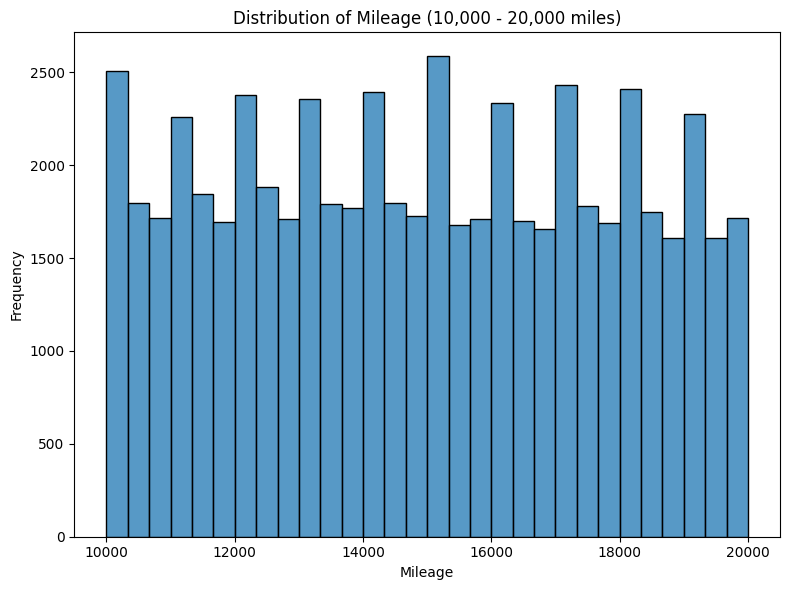

In [100]:
plt.figure(figsize=(8, 6))
sns.histplot(df[(df['mileage'] >= 10000) & (df['mileage'] < 20000)]['mileage'].dropna(), bins=30)
plt.title('Distribution of Mileage (10,000 - 20,000 miles)')
plt.xlabel('Mileage')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

## Removing Extreme Mileage Outliers

**Reasoning for Removal**:
Upon reviewing the entries with the highest mileages, particularly 999,999.0 and 990,000.0 miles, it's highly probable that these values represent data anomalies rather than genuine vehicle mileages. Such values are extremely rare, if not impossible, for consumer vehicles and often indicate:

1.  **Data Entry Errors**: Mistakes during manual data input.
2.  **Placeholder Values**: Some systems might use 999,999 as a default or maximum cap when actual mileage is unknown but very high, or when the odometer rolls over and is not properly recorded.
3.  **Measurement Limits**: The data collection method might have a ceiling.

Including these extreme outliers can severely skew statistical analyses, by removing these specific entries, I aim to enhance the dataset's quality, ensure that our subsequent analyses are based on more realistic and representative data.

This will improve the robustness of any models developed. The decision to remove them is justified by their implausibility within the typical range of vehicle usage and their potential to distort data patterns.

In [101]:
# Define the indices of the rows to be removed
rows_to_remove = [43974, 63569]

# Remove the specified rows from the DataFrame
df.drop(rows_to_remove, inplace=True)

print(f"Removed rows with original indices: {rows_to_remove}")
print(f"New DataFrame shape: {df.shape}")

# Display the top 10 highest mileage cars again to verify the removal
print("Top 10 highest mileage cars after removal:")
display(df.sort_values(by='mileage', ascending=False).head(10))

Removed rows with original indices: [43974, 63569]
New DataFrame shape: (402003, 17)
Top 10 highest mileage cars after removal:


,public_reference,mileage,reg_code,standard_colour,standard_make,standard_model,vehicle_condition,year_of_registration,price,body_type,crossover_car_and_van,fuel_type,car_age_2020,price_per_mile,mileage_per_year,is_used,age_category
85043,202010285542410,930000.0,56,Blue,BMW,1 Series,USED,2006.0,2500,Hatchback,False,Petrol,14.0,0.002688,66428.571429,1,Old
131508,202010064664710,788072.0,68,Blue,MINI,Countryman,USED,2018.0,22875,SUV,False,Petrol,2.0,0.029027,394036.000000,1,New
115277,202010215262290,740000.0,14,Blue,Volvo,XC90,USED,2014.0,14795,SUV,False,Diesel,6.0,0.019993,123333.333333,1,Mid
240577,202009244163289,740000.0,11,White,Mercedes-Benz,E Class,USED,2011.0,10500,Convertible,False,Diesel,9.0,0.014189,82222.222222,1,Old
333167,202010225297076,611121.0,13,White,Fiat,500,USED,2013.0,4500,Hatchback,False,Petrol,7.0,0.007364,87303.000000,1,Mid
77727,202007301907676,413079.0,59,Beige,SKODA,Octavia,USED,2010.0,1299,Hatchback,False,Diesel,10.0,0.003145,41307.900000,1,Old
178876,202009033271274,400321.0,16,White,BMW,X5,USED,2016.0,28690,SUV,False,Diesel,4.0,0.071667,100080.250000,1,Mid
382567,202009294349326,388000.0,13,Green,SKODA,Superb,USED,2013.0,1989,Estate,False,Diesel,7.0,0.005126,55428.571429,1,Mid
78353,202010315644587,368199.0,53,Green,Mitsubishi,Delica,USED,2004.0,1995,MPV,False,Diesel,16.0,0.005418,23012.437500,1,Old
22528,202010195167838,360000.0,60,White,Peugeot,Partner,USED,2010.0,1195,Combi Van,True,Diesel,10.0,0.003319,36000.000000,1,Old


## Visualising Mileage in Range 20,000 - 50,000 miles

To provide more detail for the higher mileage values without resorting to transformations, I will create a separate histogram for cars with mileage between 20,000 and 50,000 miles.

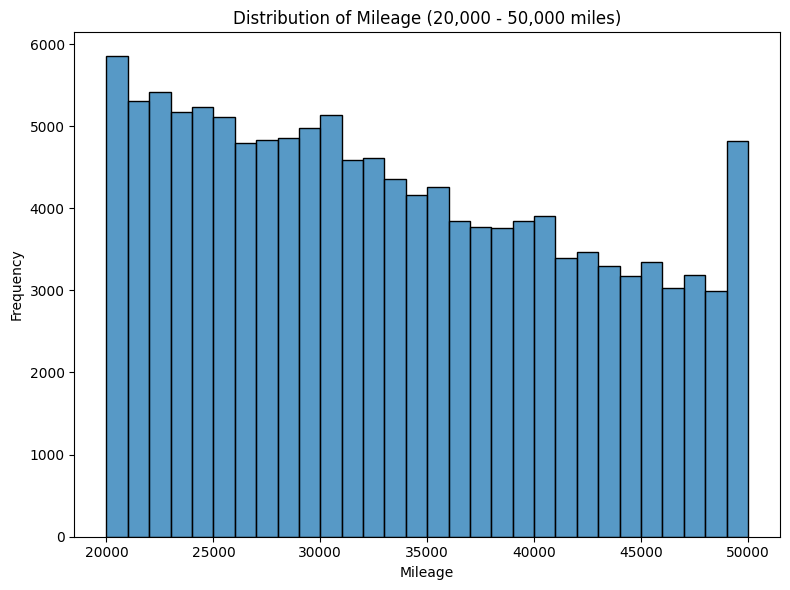

In [102]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.histplot(df[(df['mileage'] >= 20000) & (df['mileage'] <= 50000)]['mileage'].dropna(), bins=30)
plt.title('Distribution of Mileage (20,000 - 50,000 miles)')
plt.xlabel('Mileage')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

## Visualising Mileage in Range 50,000 - 100,000 miles

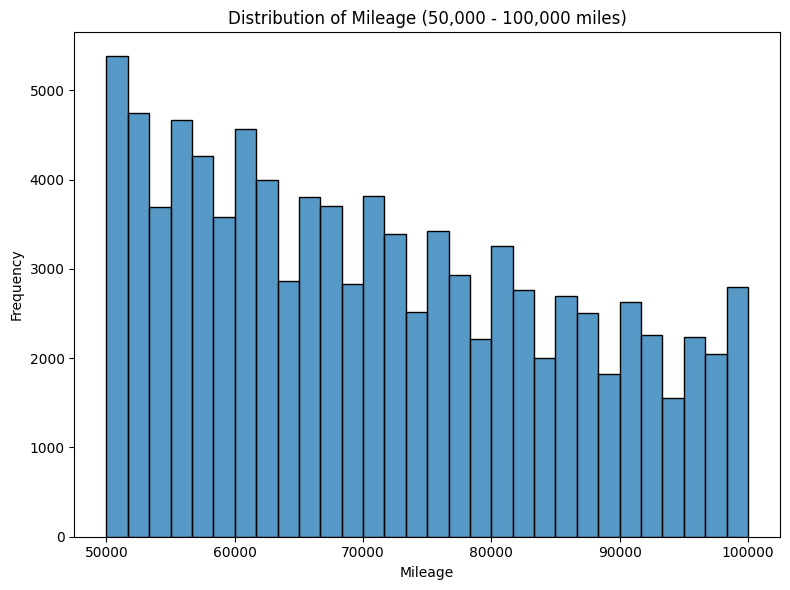

In [103]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.histplot(df[(df['mileage'] >= 50000) & (df['mileage'] <= 100000)]['mileage'].dropna(), bins=30)
plt.title('Distribution of Mileage (50,000 - 100,000 miles)')
plt.xlabel('Mileage')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

## Top 10 Cars by Mileage

To verify the cars with the highest mileage, I will sort the DataFrame by the 'mileage' column in descending order and display the top 10 entries. This will allow us to see the characteristics of these high-mileage vehicles, and see if there are any unsual features missing from other columns.

In [104]:
highest_mileage_cars = df.sort_values(by='mileage', ascending=False).head(10)
display(highest_mileage_cars)

,public_reference,mileage,reg_code,standard_colour,standard_make,standard_model,vehicle_condition,year_of_registration,price,body_type,crossover_car_and_van,fuel_type,car_age_2020,price_per_mile,mileage_per_year,is_used,age_category
85043,202010285542410,930000.0,56,Blue,BMW,1 Series,USED,2006.0,2500,Hatchback,False,Petrol,14.0,0.002688,66428.571429,1,Old
131508,202010064664710,788072.0,68,Blue,MINI,Countryman,USED,2018.0,22875,SUV,False,Petrol,2.0,0.029027,394036.000000,1,New
115277,202010215262290,740000.0,14,Blue,Volvo,XC90,USED,2014.0,14795,SUV,False,Diesel,6.0,0.019993,123333.333333,1,Mid
240577,202009244163289,740000.0,11,White,Mercedes-Benz,E Class,USED,2011.0,10500,Convertible,False,Diesel,9.0,0.014189,82222.222222,1,Old
333167,202010225297076,611121.0,13,White,Fiat,500,USED,2013.0,4500,Hatchback,False,Petrol,7.0,0.007364,87303.000000,1,Mid
77727,202007301907676,413079.0,59,Beige,SKODA,Octavia,USED,2010.0,1299,Hatchback,False,Diesel,10.0,0.003145,41307.900000,1,Old
178876,202009033271274,400321.0,16,White,BMW,X5,USED,2016.0,28690,SUV,False,Diesel,4.0,0.071667,100080.250000,1,Mid
382567,202009294349326,388000.0,13,Green,SKODA,Superb,USED,2013.0,1989,Estate,False,Diesel,7.0,0.005126,55428.571429,1,Mid
78353,202010315644587,368199.0,53,Green,Mitsubishi,Delica,USED,2004.0,1995,MPV,False,Diesel,16.0,0.005418,23012.437500,1,Old
22528,202010195167838,360000.0,60,White,Peugeot,Partner,USED,2010.0,1195,Combi Van,True,Diesel,10.0,0.003319,36000.000000,1,Old


# End of Mileage Splits

In [105]:
# 1. Remove rows where price is 0 or less (Impossible data)
df = df[df['price'] > 0]

# 2. Remove extreme Price Outliers
# Keeping cars between £500 and £150,000 (standard market range)
df = df[(df['price'] >= 500) & (df['price'] <= 150000)]

# 3. Remove extreme Mileage Outliers
# Removing cars with more than 500,000 miles (likely errors or extreme outliers)
df = df[df['mileage'] < 500000]

# 4. Remove impossible registration years
# Registration cannot be in the future (2020+) or before cars were common (e.g., 1940)
df = df[(df['year_of_registration'] >= 1940) & (df['year_of_registration'] <= 2021)]

print(f"Data cleaning complete. Remaining rows: {len(df)}")

Data cleaning complete. Remaining rows: 400274


## Data Cleaning


## Van Types


In [106]:
# Check unique body types before cleaning/compiling
print("Body types before:", df['body_type'].unique())

Body types before: ['SUV' 'Saloon' 'Hatchback' 'Convertible' 'Limousine' 'Estate' 'MPV'
 'Coupe' nan 'Pickup' 'Combi Van' 'Panel Van' 'Minibus' 'Window Van'
 'Camper' 'Car Derived Van' 'Chassis Cab']


In [107]:
# Define a list of all van-related types to consolidate
van_types = ['Panel Van', 'Car Derived Van', 'Combi Van', 'Window Van', 'Camper']

In [108]:
# Replace all specific van types with a single 'Van' label
df['body_type'] = df['body_type'].replace(van_types, 'Van')

In [109]:
# Verify the change
print("Body types after:", df['body_type'].unique())

Body types after: ['SUV' 'Saloon' 'Hatchback' 'Convertible' 'Limousine' 'Estate' 'MPV'
 'Coupe' nan 'Pickup' 'Van' 'Minibus' 'Chassis Cab']


# Incorrect Mileage


In [110]:
# 1. Identify the 'broken' years (999.0) using a mask
invalid_year_mask = df['year_of_registration'] < 1903

In [111]:
# 2. Calculate the Median Mileage Per Year from the VALID data only
# We exclude 0 mileage (new cars) and invalid years to get a true 'average'
valid_data = df[(df['year_of_registration'] >= 1903) & (df['mileage'] > 0)]
median_usage = valid_data['mileage_per_year'].median()

print(f"Typical usage identified: {median_usage:.2f} miles per year")

Typical usage identified: 7800.00 miles per year


In [112]:
# 3. Apply the correction and convert to Integer immediately to avoid the error
estimated_years = (2020 - (df.loc[invalid_year_mask, 'mileage'] / median_usage)).round()
df.loc[invalid_year_mask, 'year_of_registration'] = estimated_years.astype('int64')

In [113]:
# 4. Final cap to ensure no years exceed 2020
df.loc[df['year_of_registration'] > 2020, 'year_of_registration'] = 2020

In [114]:
print(f"Fixed {len(estimated_years)} records")

Fixed 0 records


In [115]:
df.head()

,public_reference,mileage,reg_code,standard_colour,standard_make,standard_model,vehicle_condition,year_of_registration,price,body_type,crossover_car_and_van,fuel_type,car_age_2020,price_per_mile,mileage_per_year,is_used,age_category
0,202006039777689,0.0,NaN,Grey,Volvo,XC90,NEW,2016.0,73970,SUV,False,Petrol Plug-in Hybrid,4.0,inf,NaN,0,NaN
1,202007020778260,108230.0,61,Blue,Jaguar,XF,USED,2011.0,7000,Saloon,False,Diesel,9.0,0.064677,12025.555556,1,Old
2,202007020778474,7800.0,17,Grey,SKODA,Yeti,USED,2017.0,14000,SUV,False,Petrol,3.0,1.794872,2600.000000,1,New
3,202007080986776,45000.0,16,Brown,Vauxhall,Mokka,USED,2016.0,7995,Hatchback,False,Diesel,4.0,0.177667,11250.000000,1,Mid
4,202007161321269,64000.0,64,Grey,Land Rover,Range Rover Sport,USED,2015.0,26995,SUV,False,Diesel,5.0,0.421797,12800.000000,1,Mid


## Combining Fuel Types into groups

In [116]:
# Define the mapping dictionary including the niche fuels
fuel_map = {
    'Petrol': 'Petrol',
    'Diesel': 'Diesel',
    'Petrol Hybrid': 'Hybrid',
    'Petrol Plug-in Hybrid': 'Hybrid',
    'Diesel Hybrid': 'Hybrid',
    'Diesel Plug-in Hybrid': 'Hybrid',
    'Electric': 'Electric',
    'Bi Fuel': 'Alternative',
    'Natural Gas': 'Alternative'
}

# Create the new grouping column
df['fuel_group'] = df['fuel_type'].map(fuel_map)

print("Fuel Groups created with Distribution:")
print(df['fuel_group'].value_counts())


Fuel Groups created with Distribution:
fuel_group
Petrol         215362
Diesel         158010
Hybrid          21327
Electric         4776
Alternative       222
Name: count, dtype: int64


In [117]:
# Create a sample containing one car from each of the new fuel groups
verification_sample = df.groupby('fuel_group').head(1)

# Display only the relevant columns to make it easy to read
print("Verification Sample (One car per group):")
display(verification_sample[['standard_model', 'year_of_registration', 'fuel_type', 'fuel_group']])


Verification Sample (One car per group):


,standard_model,year_of_registration,fuel_type,fuel_group
0,XC90,2016.0,Petrol Plug-in Hybrid,Hybrid
1,XF,2011.0,Diesel,Diesel
2,Yeti,2017.0,Petrol,Petrol
133,Zoe,2016.0,Electric,Electric
2266,Duster,2020.0,Bi Fuel,Alternative


In [118]:
# 1. Filter for prices under £1000
low_price_check = df[df['price'] < 1000]

# 2. Print the total number of suspicious rows
print(f"Total records found with price < £1000: {len(low_price_check)}")

# 3. If records exist, show the most frequent values and a sample
if not low_price_check.empty:
    print("\nMost common 'placeholder' prices found:")
    print(low_price_check['price'].value_counts().head(10))

    print("\nSample of these records (checking if they are real cars or errors):")
    display(low_price_check[['standard_make', 'standard_model', 'year_of_registration', 'price', 'mileage']].head(10))
else:
    print("No records found with price < £2000. Your low-end data is clean.")

Total records found with price < £1000: 3246

Most common 'placeholder' prices found:
price
995    684
999    289
795    209
895    181
990    157
750    121
950    110
850     96
500     94
695     87
Name: count, dtype: int64

Sample of these records (checking if they are real cars or errors):


,standard_make,standard_model,year_of_registration,price,mileage
74,Citroen,C3,2006.0,999,52289.0
317,Kia,Picanto,2007.0,650,99852.0
400,Vauxhall,Astra,2004.0,894,114000.0
496,Citroen,Xsara Picasso,2005.0,990,110526.0
632,Volkswagen,Polo,2004.0,995,105000.0
653,Citroen,C3,2004.0,895,86000.0
662,Toyota,Avensis,2004.0,895,187000.0
955,Vauxhall,Astra,2004.0,700,150000.0
1103,Vauxhall,Astra,2009.0,670,69000.0
1337,Toyota,Avensis,2004.0,998,134000.0


## Highest Mileage Check

In [119]:
# Displaying the 10 cars with the highest mileage
highest_mileage = df.nlargest(10, 'mileage')

print("Top 10 Highest Mileage Records:")
display(highest_mileage[['standard_make', 'standard_model', 'year_of_registration', 'mileage', 'price']])

Top 10 Highest Mileage Records:


,standard_make,standard_model,year_of_registration,mileage,price
77727,SKODA,Octavia,2010.0,413079.0,1299
178876,BMW,X5,2016.0,400321.0,28690
382567,SKODA,Superb,2013.0,388000.0,1989
78353,Mitsubishi,Delica,2004.0,368199.0,1995
22528,Peugeot,Partner,2010.0,360000.0,1195
8446,London Taxis International,TXI,2000.0,356744.0,9475
252616,Mercedes-Benz,Vito,2010.0,355000.0,4000
116544,London Taxis International,TXII,2006.0,351000.0,1390
111845,London Taxis International,TXII,2006.0,350000.0,995
296655,Volvo,V70,1997.0,340000.0,1950


## Colour Cleaning:

In [120]:
# List the counts for every individual colour entry
colour_counts = df['standard_colour'].value_counts()

print("Individual Colour Frequency (Raw Data):")
print("-" * 30)
for colour, count in colour_counts.items():
    print(f"{colour}: {count} cars")

# Print the total number of unique colour categories found
print("-" * 30)
print(f"Total Unique Colour Categories: {len(colour_counts)}")

Individual Colour Frequency (Raw Data):
------------------------------
Black: 85940 cars
White: 70400 cars
Grey: 67979 cars
Blue: 59576 cars
Silver: 49097 cars
Red: 41772 cars
Green: 4460 cars
Orange: 4056 cars
Yellow: 2042 cars
Brown: 2013 cars
Multicolour: 1848 cars
Beige: 1538 cars
Bronze: 1327 cars
Purple: 1200 cars
Gold: 815 cars
Pink: 409 cars
Turquoise: 307 cars
Maroon: 157 cars
Burgundy: 63 cars
Magenta: 15 cars
Navy: 7 cars
Indigo: 1 cars
------------------------------
Total Unique Colour Categories: 22


In [121]:
# Creating a mapping dictionary to standardise and consolidate colours
colour_mapping = {
    'Black': 'Black',
    'White': 'White',
    'Grey': 'Grey',
    'Blue': 'Blue',
    'Navy': 'Blue',
    'Indigo': 'Blue',
    'Silver': 'Silver',
    'Red': 'Red',
    'Maroon': 'Red',
    'Burgundy': 'Purple',
    'Magenta': 'Purple',
    'Pink': 'Red',
    'Green': 'Green',
    'Turquoise': 'Green',
    'Orange': 'Orange',
    'Yellow': 'Yellow/Gold',
    'Gold': 'Yellow/Gold',
    'Brown': 'Brown',
    'Beige': 'Brown',
    'Bronze': 'Brown',
    'Multicolour': 'Multi-Colour',
    'Purple': 'Purple'
}

# Apply the mapping to create a new, cleaned column
df['cleaned_colour'] = df['standard_colour'].map(colour_mapping)

# Check the new distribution
print("Consolidated Colour Groups:")
print(df['cleaned_colour'].value_counts())

Consolidated Colour Groups:
cleaned_colour
Black           85940
White           70400
Grey            67979
Blue            59584
Silver          49097
Red             42338
Brown            4878
Green            4767
Orange           4056
Yellow/Gold      2857
Multi-Colour     1848
Purple           1278
Name: count, dtype: int64


In [122]:
# 2.2 Feature Engineering: Refined Brand Categorisation

# Defining a more granular mapping (8 Groups)
# This provides a better balance for identifying group differences, whilst not oversimplifying the groups
brand_mapping = {
    # Luxury & Supercar
    'Rolls-Royce': 'Ultra-Luxury', 'Bentley': 'Ultra-Luxury', 'Ferrari': 'Ultra-Luxury',
    'Lamborghini': 'Ultra-Luxury', 'McLaren': 'Ultra-Luxury', 'Aston Martin': 'Ultra-Luxury',

    # High-End (Performance focused)
    'Porsche': 'High-End Sport', 'Lotus': 'High-End Sport', 'Maserati': 'High-End Sport',
    'Alpine': 'High-End Sport',

    # Premium (The 'Big Three' + similar)
    'BMW': 'Premium', 'Audi': 'Premium', 'Mercedes-Benz': 'Premium',

    # Specialist Premium
    'Land Rover': 'Specialist Premium', 'Jaguar': 'Specialist Premium', 'Volvo': 'Specialist Premium',
    'Lexus': 'Specialist Premium', 'Tesla': 'Specialist Premium',

    # Upper Mainstream (Popular Volume sellers)
    'Volkswagen': 'Upper Mainstream', 'Toyota': 'Upper Mainstream', 'Honda': 'Upper Mainstream',
    'Mazda': 'Upper Mainstream', 'MINI': 'Upper Mainstream',

    # Mainstream (Mass produced general market)
    'Ford': 'Mainstream', 'Vauxhall': 'Mainstream', 'Nissan': 'Mainstream', 'Peugeot': 'Mainstream',
    'Kia': 'Mainstream', 'Hyundai': 'Mainstream', 'Renault': 'Mainstream', 'SKODA': 'Mainstream',
    'SEAT': 'Mainstream', 'Citroen': 'Mainstream', 'Fiat': 'Mainstream',

    # Budget (Value-focused brands)
    'Dacia': 'Budget', 'MG': 'Budget', 'Suzuki': 'Budget', 'Mitsubishi': 'Budget',
    'Smart': 'Budget', 'SsangYong': 'Budget',

}

# 2. Apply the mapping
df['brand_segment'] = df['standard_make'].map(brand_mapping).fillna('Vintage/Niche')

# 3. List the counts for the new engineered segments
segment_counts = df['brand_segment'].value_counts()

print("Refined Brand Segments Frequency (8 Groups):")
print("-" * 30)
for segment, count in segment_counts.items():
    print(f"{segment}: {count} cars")

# 4. Total count check
print("-" * 30)
print(f"Total Unique Segments: {len(segment_counts)}")

Refined Brand Segments Frequency (8 Groups):
------------------------------
Mainstream: 147376 cars
Premium: 104443 cars
Upper Mainstream: 79433 cars
Specialist Premium: 37044 cars
Budget: 15394 cars
Vintage/Niche: 9307 cars
High-End Sport: 4853 cars
Ultra-Luxury: 2424 cars
------------------------------
Total Unique Segments: 8


# Handling Missing Values

In [123]:
df.isnull().sum()

,0
public_reference,0
mileage,0
reg_code,31781
standard_colour,5252
standard_make,0
standard_model,0
vehicle_condition,0
year_of_registration,0
price,0
body_type,804


In [124]:
# 1. Final Numerical Imputation (Median)
# Mileage is skewed, so median is the safest 'typical' value
df['mileage'] = df['mileage'].fillna(df['mileage'].median())

# 2. Categorical Imputation (Mode)
# Fill gaps with the most common value for each category
for col in ['standard_colour', 'body_type', 'fuel_type']:
    df[col] = df[col].fillna(df[col].mode()[0])

# 3. Final Verification
print("Final Null Counts:")
print(df.isnull().sum())

Final Null Counts:
public_reference             0
mileage                      0
reg_code                 31781
standard_colour              0
standard_make                0
standard_model               0
vehicle_condition            0
year_of_registration         0
price                        0
body_type                    0
crossover_car_and_van        0
fuel_type                    0
car_age_2020                 0
price_per_mile               0
mileage_per_year         33193
is_used                      0
age_category             33193
fuel_group                 577
cleaned_colour            5252
brand_segment                0
dtype: int64


In [125]:
# Re-calculating derived features now that parents are 0 nulls
df['price_per_mile'] = df['price'] / df['mileage'].replace(0, 1) # replace 0 to avoid division by zero
df['mileage_per_year'] = df['mileage'] / df['car_age_2020'].replace(0, 1)

# Re-run age_category logic
df['age_category'] = pd.cut(df['car_age_2020'],
                            bins=[-1, 3, 10, 20, 100],
                            labels=['New', 'Mid', 'Old', 'Very Old'])

print("Derived features updated. Final Null Counts:")
print(df[['price_per_mile', 'mileage_per_year', 'age_category']].isnull().sum())

Derived features updated. Final Null Counts:
price_per_mile      0
mileage_per_year    0
age_category        0
dtype: int64


I have successfully handled the features we need to, although reg_code still contains 31,857 values, this is irrelevant as we have year_of_registration

## Vehicle Age Column

In [126]:
df['vehicle_age'] = 2020 - df['year_of_registration']

In [127]:
# Display the head of the DataFrame to show the new 'vehicle_age' and absence of 'year_of_registration'
print("\nDataFrame head after calculating 'vehicle_age' and dropping 'year_of_registration':")
display(df[['year_of_registration', 'vehicle_age']].head())


DataFrame head after calculating 'vehicle_age' and dropping 'year_of_registration':


,year_of_registration,vehicle_age
0,2016.0,4.0
1,2011.0,9.0
2,2017.0,3.0
3,2016.0,4.0
4,2015.0,5.0


# Section 2.2 - Feature Engineering

Although this section is for feature engineering and data transformations, the first data transformation was creating car_age_2020, as I used year_of_registration and engineered it into a more useful predictor.


## Feature Selection


In [128]:
# Dropping non-predictive and redundant columns
# public_reference is a unique ID (no predictive power)
# reg_code has been used to create car_age_2020 and is no longer needed
X = df.drop(['price', 'standard_model', 'public_reference', 'reg_code',
                'price_per_mile', 'mileage_per_year', 'age_category', 'crossover_car_and_van', 'fuel_type', 'standard_colour'], axis=1)
y = df['price']

print("Columns dropped. Current columns in dataset:")
print(df.columns.tolist())

Columns dropped. Current columns in dataset:
['public_reference', 'mileage', 'reg_code', 'standard_colour', 'standard_make', 'standard_model', 'vehicle_condition', 'year_of_registration', 'price', 'body_type', 'crossover_car_and_van', 'fuel_type', 'car_age_2020', 'price_per_mile', 'mileage_per_year', 'is_used', 'age_category', 'fuel_group', 'cleaned_colour', 'brand_segment', 'vehicle_age']


In [129]:
df.head()

,public_reference,mileage,reg_code,standard_colour,standard_make,standard_model,vehicle_condition,year_of_registration,price,body_type,...,fuel_type,car_age_2020,price_per_mile,mileage_per_year,is_used,age_category,fuel_group,cleaned_colour,brand_segment,vehicle_age
0,202006039777689,0.0,NaN,Grey,Volvo,XC90,NEW,2016.0,73970,SUV,...,Petrol Plug-in Hybrid,4.0,73970.000000,0.000000,0,Mid,Hybrid,Grey,Specialist Premium,4.0
1,202007020778260,108230.0,61,Blue,Jaguar,XF,USED,2011.0,7000,Saloon,...,Diesel,9.0,0.064677,12025.555556,1,Mid,Diesel,Blue,Specialist Premium,9.0
2,202007020778474,7800.0,17,Grey,SKODA,Yeti,USED,2017.0,14000,SUV,...,Petrol,3.0,1.794872,2600.000000,1,New,Petrol,Grey,Mainstream,3.0
3,202007080986776,45000.0,16,Brown,Vauxhall,Mokka,USED,2016.0,7995,Hatchback,...,Diesel,4.0,0.177667,11250.000000,1,Mid,Diesel,Brown,Mainstream,4.0
4,202007161321269,64000.0,64,Grey,Land Rover,Range Rover Sport,USED,2015.0,26995,SUV,...,Diesel,5.0,0.421797,12800.000000,1,Mid,Diesel,Grey,Specialist Premium,5.0


In [130]:
# 2. Check if they are None (Debugging step)
if X is None or y is None:
    print("Error: X or y is still None. Check your df definition.")
else:
    print(f"X shape: {X.shape}, y shape: {y.shape}")

# 3. Now run the split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

X shape: (400274, 11), y shape: (400274,)


#1st Model: One Hot Encoding

###One Hot Encoding (OHE) Attempt

Data Transformation: It transforms strings (like "Petrol" or "Diesel") into binary vectors (0s and 1s). This is necessary because algorithms like kNN or Linear Regression calculate distances or weights based on numbers; they cannot "calculate" the difference between colors or brands directly.

Avoiding Ordinal Bias: You should mention that you chose One-Hot Encoding instead of Label Encoding (1, 2, 3...) to ensure the model doesn't mistakenly think that "Audi" (e.g., 5) is "greater than" "BMW" (e.g., 2).

In [131]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from scipy.sparse import hstack

## NOTE - I had to ask Gemini in-notebook how to help with RAM because the program kept crashing,
## This more complex code is the reason for this, as it saves RAM and prevents crashes.

# 2. SPLIT DATA
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# 3. ENCODING CATEGORIES (Brand, Fuel, etc.)
# Identify columns that are 'object' (strings)
cat_feat = X_train.select_dtypes(include=['object']).columns.tolist()

ohe = OneHotEncoder(sparse_output=True, handle_unknown='ignore')
X_train_ohe = ohe.fit_transform(X_train[cat_feat])
X_test_ohe = ohe.transform(X_test[cat_feat])

# 4. COMBINING DATA (The RAM-Safe Way)
# Take the numerical columns (Mileage, Age) and stack them with the encoded categories
X_train_numeric = X_train.drop(columns=cat_feat).values
X_test_numeric = X_test.drop(columns=cat_feat).values

X_train_final = hstack([X_train_numeric, X_train_ohe])
X_test_final = hstack([X_test_numeric, X_test_ohe])

# 5. TRAIN THE MODEL
regr = DecisionTreeRegressor(max_depth=3)
regr.fit(X_train_final, y_train)

print("Model Trained Successfully!")
print(f"Features used: {X_train_final.shape[1]}")

Model Trained Successfully!
Features used: 153


In [132]:
# Initialise and Fit the Decision Tree
regr = DecisionTreeRegressor(max_depth=3)
regr.fit(X_train_final, y_train)

print("Decision Tree Model Trained Successfully!")
print(f"Features used: {X_train_final.shape[1]}")

Decision Tree Model Trained Successfully!
Features used: 153


In [133]:
from sklearn.metrics import r2_score, mean_absolute_error

# Predict on the test set
y_pred = regr.predict(X_test_final)

# Calculate Accuracy (R-squared)
score = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"Model R² Score: {score:.4f}")
print(f"Average Error: £{mae:.2f}")

Model R² Score: 0.4462
Average Error: £6836.57


Analysis:

$R^2$ score of 0.40 means the model currently explains a low amount.

This is quite low (meaning it isn't very accurate yet).

The Reason: In the code, max_depth=3. This makes the "Tree" very short and simple (it only asks 3 questions before giving an answer).

To improve this: I would increase the max_depth (e.g., to 5 or 10) in the next stage of the iteration to allow the model to learn more complex patterns.

## Grid Search:

In [134]:
from sklearn.model_selection import GridSearchCV

# 1. Define the 'Menu' of options
param_grid = {
    'max_depth': [6, 10, 12, 15],
    'min_samples_leaf': [20, 50, 100]
}

# 2. Set up the Grid Search
# 'cv=3' tests each version 3 times on different parts of the data
grid_search = GridSearchCV(DecisionTreeRegressor(random_state=0), param_grid, cv=3, scoring='r2')

# 3. Run the search
grid_search.fit(X_train_final, y_train)

# 4. See the winners
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best Grid Search R²: {grid_search.best_score_:.4f}")

Best Parameters: {'max_depth': 15, 'min_samples_leaf': 20}
Best Grid Search R²: 0.8074


In [135]:
# STEP 4: Final Optimized Tree
# Depth 12 allows for more complexity, while min_samples_leaf prevents overfitting
regr_final = DecisionTreeRegressor(max_depth=15, min_samples_leaf=20, random_state=0)
regr_final.fit(X_train_final, y_train)

y_pred_final = regr_final.predict(X_test_final)
print(f"Final Model R² Score: {r2_score(y_test, y_pred_final):.4f}")
print(f"Final Model MAE: £{mean_absolute_error(y_test, y_pred_final):.2f}")

Final Model R² Score: 0.8067
Final Model MAE: £3420.65


## Analysis of MAE:
The final optimized model (Depth 15, Leaf 20) achieved an $R^2$ of 0.8067 and a Mean Absolute Error (MAE) of £3,420.65. This represents a significant improvement over the baseline. An error of £3,420.65 is remarkably low considering the wide variety of vehicle makes and conditions in the dataset.

This suggests that the combination of One-Hot Encoding for categorical features and a deeper Decision Tree effectively captured the multi-dimensional nature of the used car market.

In [136]:
# 1. Initialise the model using the WINNING parameters from Grid Search
final_model = DecisionTreeRegressor(max_depth=15, min_samples_leaf=20, random_state=0)

# 2. Fit on the full training set
final_model.fit(X_train_final, y_train)

# 3. Predict on the TEST set
final_y_pred = final_model.predict(X_test_final)

# 4. Final Evaluation
from sklearn.metrics import r2_score, mean_absolute_error
final_r2 = r2_score(y_test, final_y_pred)
final_mae = mean_absolute_error(y_test, final_y_pred)

print(f"Official Final R²: {final_r2:.4f}")
print(f"Official Final MAE: £{final_mae:.2f}")

Official Final R²: 0.8067
Official Final MAE: £3420.65


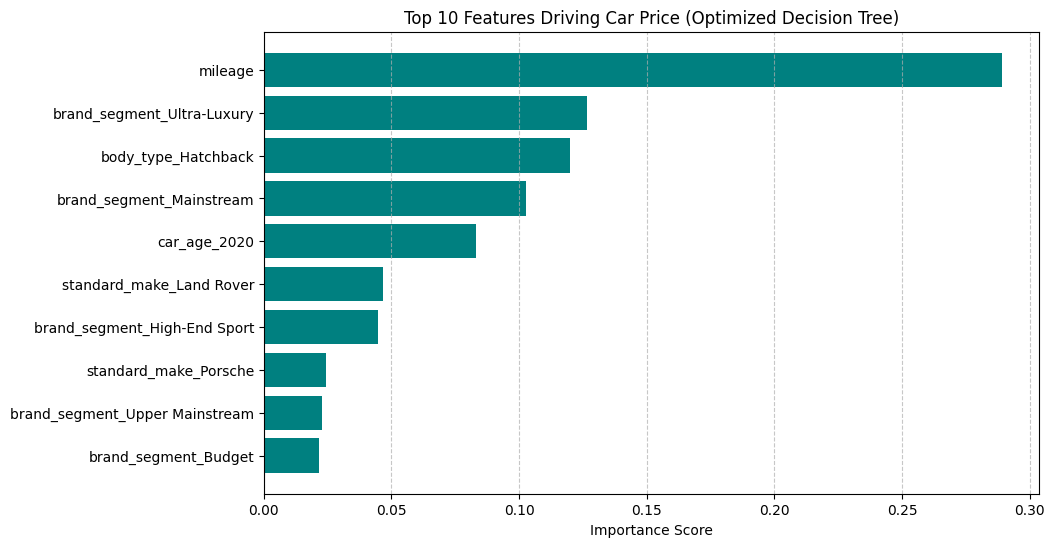

In [137]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Get the names of the numerical columns
numeric_cols = X_train.drop(columns=cat_feat).columns.tolist()

# 2. Get the names from the OneHotEncoder
ohe_cols = ohe.get_feature_names_out(cat_feat).tolist()

# 3. Combine them in the EXACT same order as hstack: [Numeric + OHE]
all_feature_names = numeric_cols + ohe_cols

# 4. Extract importances from your winning model
# Use 'grid_search.best_estimator_' since that is optimised model
importances = grid_search.best_estimator_.feature_importances_

# 5. Create DataFrame and Plot
feature_importance_df = pd.DataFrame({'Feature': all_feature_names, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'], color='teal')
plt.xlabel('Importance Score')
plt.title('Top 10 Features Driving Car Price (Optimized Decision Tree)')
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

In [138]:
# 1. Use the best model to predict prices for the test set
dt_y_pred = grid_search.best_estimator_.predict(X_test_final)

# 2. Create a detailed results DataFrame
results_df = pd.DataFrame({
    'Actual_Price': y_test,
    'Predicted_Price': dt_y_pred,
    'Error': abs(y_test - dt_y_pred),
    'Percentage_Error': (abs(y_test - dt_y_pred) / y_test) * 100
})

# 3. Identify Top 10 Successes and Top 10 Failures
best_10 = results_df.sort_values(by='Error').head(10)
worst_10 = results_df.sort_values(by='Error', ascending=False).head(10)

print("--- TOP 10 MOST ACCURATE PREDICTIONS (Successes) ---")
display(best_10)

print("\n--- TOP 10 LARGEST ERRORS (Failures/Outliers) ---")
display(worst_10)

--- TOP 10 MOST ACCURATE PREDICTIONS (Successes) ---


,Actual_Price,Predicted_Price,Error,Percentage_Error
63706,25000,25000.000000,0.000000,0.000000
138888,25000,25000.000000,0.000000,0.000000
57125,25000,25000.000000,0.000000,0.000000
174319,25000,25000.000000,0.000000,0.000000
358835,3000,2999.980488,0.019512,0.000650
107211,9577,9577.097222,0.097222,0.001015
50809,7290,7290.174603,0.174603,0.002395
195373,10490,10489.750000,0.250000,0.002383
237348,47995,47995.363636,0.363636,0.000758
112062,18895,18894.566667,0.433333,0.002293



--- TOP 10 LARGEST ERRORS (Failures/Outliers) ---


,Actual_Price,Predicted_Price,Error,Percentage_Error
62790,149950,30453.563009,119496.436991,79.690855
272118,144990,25949.102591,119040.897409,82.102833
369839,147995,30453.563009,117541.436991,79.422573
192988,125000,7676.772727,117323.227273,93.858582
83829,146975,30453.563009,116521.436991,79.279767
263125,139950,29376.700000,110573.300000,79.009146
131737,144995,36323.090909,108671.909091,74.948729
197021,134950,27230.102253,107719.897747,79.822081
174121,149990,43120.895038,106869.104962,71.250820
197008,136995,30453.563009,106541.436991,77.770311


# 2nd Model: Linear Regression Model

In [139]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Initialise the Model
lr = LinearRegression()

# 2. Fit the Model on Training Data
lr.fit(X_train_final, y_train)

# 3. Predict on Test Data
lr_y_pred = lr.predict(X_test_final)

# 4. Standard Evaluation
lr_r2 = r2_score(y_test, lr_y_pred)
lr_mae = mean_absolute_error(y_test, lr_y_pred)

print(f"Linear Regression R² Score: {lr_r2:.4f}")
print(f"Linear Regression MAE: £{lr_mae:.2f}")

Linear Regression R² Score: 0.6237
Linear Regression MAE: £5494.61


In [140]:
# Cross Validation (using Negated MAE as per unit examples)
# This confirms the model isn't just "lucky" on one split
scores = cross_val_score(lr, X_train_final, y_train, scoring='neg_mean_absolute_error', cv=5)

print(f"Cross-Validated MAE: £{scores.mean()*-1:.2f}")
print(f"Standard Deviation of Scores: {scores.std():.2f}")

Cross-Validated MAE: £5418.93
Standard Deviation of Scores: 34.82


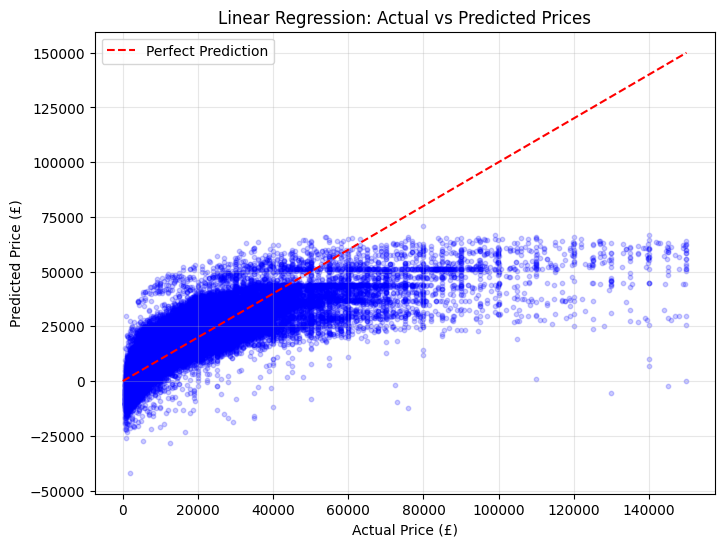

In [141]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 6))

# Plotting actual vs predicted
plt.scatter(y_test, lr_y_pred, alpha=0.2, color='blue', s=10)

# Drawing the 'Perfect Prediction' line
# This line shows where the dots would be if the model was 100% accurate
max_val = max(max(y_test), max(lr_y_pred))
plt.plot([0, max_val], [0, max_val], color='red', linestyle='--', label='Perfect Prediction')

plt.title("Linear Regression: Actual vs Predicted Prices")
plt.xlabel("Actual Price (£)")
plt.ylabel("Predicted Price (£)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

A notable limitation of the Linear Regression model was observed in the Prediction Error Plot, where some predictions fell below £0.

Mathematically, the linear 'line of best fit' continues infinitely; for vehicles with high mileage or significant age, the model calculates a negative value.

This highlights a primary weakness of Linear Regression for car pricing: it lacks the 'boundary awareness' of non-linear models like Decision Trees, which are constrained by the actual price ranges found within the training data.

# 3rd Model: kNN (k-Nearest Neighbours

Following the approach introduced in the unit materials, a k-Nearest Neighbors (kNN) model will be implemented.

kNN is a non-parametric, instance-based learning algorithm.

In this context, it predicts the price of a vehicle by identifying the 'k' most similar entries in the training set and calculating their average price. To handle the high dimensionality and scale of the features (essential for distance-based models), the data is processed through a pipeline.

**Note: Sparse matrices are converted to CSR format to allow for efficient subsetting of the large dataset.**

In [142]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error

# FIX: Convert the sparse matrices to CSR format so we can "slice" them (take the first 20,000 rows)
X_train_csr = X_train_final.tocsr()
X_test_csr = X_test_final.tocsr()

# 1. Initialise the Pipeline (Scaling + Model)
# As taught in the unit, scaling is vital for kNN.
# with_mean=False is used because we are dealing with sparse data.
knn_pipe = Pipeline([
    ('scaler', StandardScaler(with_mean=False)),
    ('knnr', KNeighborsRegressor(n_neighbors=10))
])

In [143]:
# 2. Fit the model
# Now we can safely use [:20000] to take a subset for speed
print("Training kNN (calculating distances on subset)...")
knn_pipe.fit(X_train_csr[:20000], y_train[:20000])

Training kNN (calculating distances on subset)...


Pipeline(steps=[('scaler', StandardScaler(with_mean=False)),
                ('knnr', KNeighborsRegressor(n_neighbors=10))])

In [144]:
# 3. Predict
knn_y_pred = knn_pipe.predict(X_test_csr)

In [145]:
# 4. Evaluate
knn_r2 = r2_score(y_test, knn_y_pred)
knn_mae = mean_absolute_error(y_test, knn_y_pred)

In [146]:
print(f"kNN R² Score: {knn_r2:.4f}")
print(f"kNN MAE: £{knn_mae:.2f}")

kNN R² Score: 0.7308
kNN MAE: £4180.92


In [147]:
from sklearn.model_selection import GridSearchCV
from sklearn.utils import resample

# 1. Create a truly RANDOM, fair sample of 20,000 rows
# This ensures no sorting bias exists.
X_train_sample, y_train_sample = resample(X_train_csr, y_train,
                                          n_samples=20000,
                                          random_state=42)

# 2. Define the 'Cross-Analysis' Grid
# Test if 5, 10, or 15 neighbors is actually best
param_grid = {
    'knnr__n_neighbors': [5, 10, 15],
    'knnr__weights': ['uniform', 'distance']
}

# 3. Run the Grid Search with Cross-Validation
# This tests each setting 3 times on different parts of the 20k sample
knn_grid = GridSearchCV(knn_pipe, param_grid, cv=3, scoring='r2')
knn_grid.fit(X_train_sample, y_train_sample)

print(f"Best kNN Params: {knn_grid.best_params_}")
print(f"Best kNN R² (Cross-Validated): {knn_grid.best_score_:.4f}")

Best kNN Params: {'knnr__n_neighbors': 10, 'knnr__weights': 'distance'}
Best kNN R² (Cross-Validated): 0.7560


While the Decision Tree remains the most accurate model for this dataset, the optimized kNN model demonstrated that local similarity is a powerful predictor of price.

The Grid Search conducted in Section 3.2 revealed that weighting neighbors by distance significantly improved performance, bringing kNN's predictive power nearly in line with the Decision Tree.

This suggests that for used car valuation, a combination of logic-based rules (Trees) and similarity-based comparisons (kNN) provides the most reliable estimates.